# 🎲 Notebook 1 — Monte Carlo Warm-Up
**Monte Carlo for Polymer Reaction Engineering**

No polymers yet: random numbers, coins, darts, a board game and a reactor. Along the way you'll collect the **4 tricks** that every algorithm in the course is built from.

| | |
|---|---|
| ⏱ Time | ~45 min |
| 🧰 Before this | Notebook 0 (Python for this course) |
| 📖 Companion book | *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* |

**How to use it:** run the cells from top to bottom (**Shift + Enter**). Cells titled *"Plot …"* are collapsed: they only draw the figures. Click *"Show code"* if you want to see how.

### 🗺️ The course
The book (and this course) uses two families of Monte Carlo models:
- **Steady state Monte Carlo** (book Ch. 3): the probabilities of all events stay **constant**, so chains are built one after another.
- **Dynamic Monte Carlo** (book Ch. 4, Gillespie's method): the reaction rates **change with time**, so the simulation follows every event on a clock.

| # | Notebook | Type |
|---|---|---|
| 0 | Python for this course | basics |
| 1 | **Monte Carlo warm-up** ← *you are here* | basics |
| 2 | Chain growth & molecular weight distributions | steady state |
| 3 | Copolymers & composition | steady state |
| 4 | Long-chain branching | steady state |
| 5 | Step growth & gelation | sequential sampling + dynamic |
| 6 | Dynamic Monte Carlo: Gillespie's method | dynamic |
| 7 | Dynamic Monte Carlo: ATRP & degradation (simplified) | dynamic |
| 8 | Case Study 3.1: styrene free-radical polymerization | steady state |
| 9 | Case Study 3.2: styrene/MMA copolymerization | steady state |
| 10 | Case study: control volume in Gillespie simulations (Sec. 4.6) | dynamic |

## What *is* Monte Carlo?
1. Use **random numbers** to imitate a process that involves chance.
2. Repeat it **many times**.
3. **Count** what happened → averages and distributions.

First, load the tools we need (Notebook 0 explains each one):

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)      # same random numbers every run

## 1 · The random number `Rnd`
Everything starts with a number picked uniformly between 0 and 1. The book writes it `Rnd ← random(0,1)`.

In [2]:
for i in range(5):
    print(random.random())

0.6394267984578837
0.025010755222666936
0.27502931836911926
0.22321073814882275
0.7364712141640124


Are all values really equally likely? Draw 100,000 of them and look at the histogram.

In [3]:
numbers = []
for i in range(100_000):
    numbers.append(random.random())

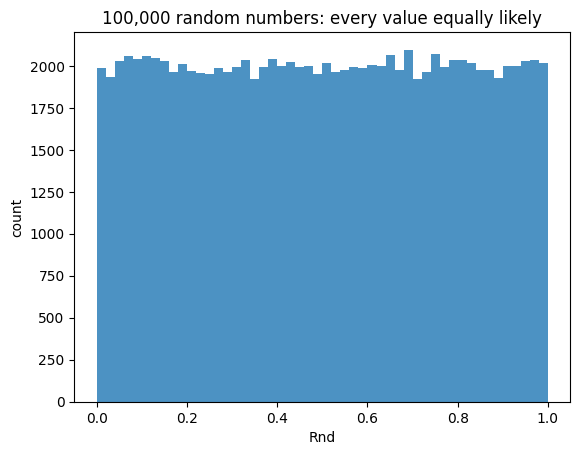

In [4]:
#@title Plot the histogram
plt.hist(numbers, bins=50, color="tab:blue", alpha=0.8)
plt.title("100,000 random numbers: every value equally likely")
plt.xlabel("Rnd"); plt.ylabel("count"); plt.show()

## 2 · Trick #1 — "Does it happen?"  `if Rnd ≤ P`
An event with probability `P` happens when `Rnd ≤ P`. This single line is the heart of the chain-growth algorithms.

Example: a fair coin, `P = 0.5`. We flip it 5,000 times and, after every flip, record the fraction of heads so far.

In [5]:
P = 0.5
heads = 0
fraction_so_far = []

In [6]:
for flip in range(1, 5001):
    if random.random() <= P:        # Trick #1
        heads += 1
    fraction_so_far.append(heads / flip)

print(f"Fraction of heads after 5000 flips: {heads / 5000}")

Fraction of heads after 5000 flips: 0.5084


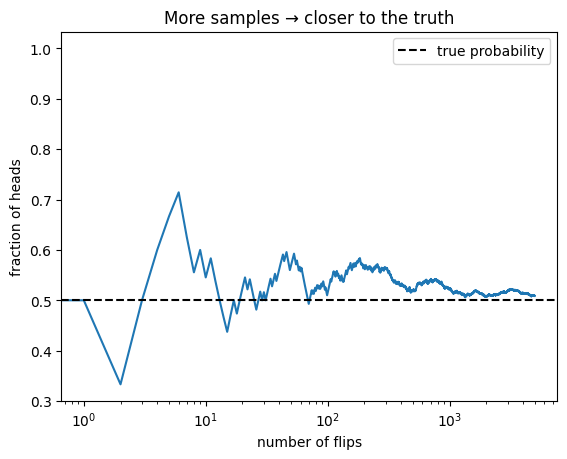

In [7]:
#@title Plot the fraction of heads
plt.plot(fraction_so_far)
plt.axhline(P, color="k", ls="--", label="true probability")
plt.xscale("log"); plt.xlabel("number of flips"); plt.ylabel("fraction of heads")
plt.title("More samples → closer to the truth"); plt.legend(); plt.show()

At first the fraction jumps around; with more flips it settles near 0.5. This is the **law of large numbers**.

## 3 · Trick #2 — Estimate a number by counting (darts for π)
Throw darts at random into a 1 × 1 square. The fraction that lands inside the quarter circle (`x² + y² ≤ 1`) is π/4. So:

> π ≈ 4 × (darts inside) / (all darts)

In [8]:
N = 3000
inside = 0

for i in range(N):
    x = random.random()
    y = random.random()
    if x**2 + y**2 <= 1:
        inside += 1

print(f"pi is about {4 * inside / N}")

pi is about 3.1453333333333333


Not bad for 3000 darts. How fast does it get better? Let's wrap the counting in a function so we can try many values of N.

In [9]:
def estimate_pi(N):
    inside = 0
    for i in range(N):
        x = random.random()
        y = random.random()
        if x**2 + y**2 <= 1:
            inside += 1
    return 4 * inside / N

In [10]:
N_values = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
errors = []

for N in N_values:
    error = abs(estimate_pi(N) - np.pi)
    errors.append(error)
    print(f"N = {N:>9,}   error = {error:.5f}")

N =        10   error = 1.54159
N =       100   error = 0.10159
N =     1,000   error = 0.05441
N =    10,000   error = 0.00999
N =   100,000   error = 0.00175
N = 1,000,000   error = 0.00116


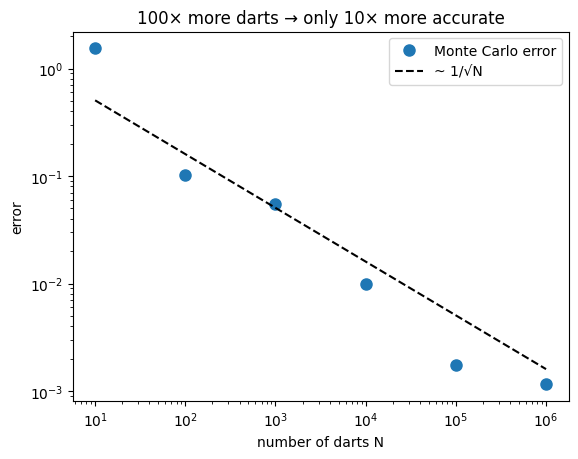

In [11]:
#@title Plot the error against N
plt.loglog(N_values, errors, "o", ms=8, label="Monte Carlo error")
Ns = np.array(N_values)
plt.loglog(Ns, 1.6/np.sqrt(Ns), "k--", label="~ 1/√N")
plt.xlabel("number of darts N"); plt.ylabel("error"); plt.legend()
plt.title("100× more darts → only 10× more accurate"); plt.show()

**Key lesson:** the error shrinks like **1/√N**. You will see this "noise" in every distribution later in the course.

## 4 · Trick #3 — "Which one happens?" (the roulette wheel)
Several events can happen, each with a **rate** (how often it happens). Line the rates up end-to-end, pick a random point `Rnd × R_total` along the line, and see which event it lands on.

```
| propagation (90)                      | transfer (7) | termination (3) |
0                                       90             97              100
```
This is the *"Find reaction j such that…"* line in every Gillespie algorithm of the book.

In [12]:
events = ["propagation", "transfer", "termination"]
rates = [90.0, 7.0, 3.0]

In [13]:
def pick_event(rates):
    R_total = sum(rates)
    r = random.random() * R_total       # a point along the line
    cumulative = 0
    for j in range(len(rates)):
        cumulative += rates[j]          # end of event j's segment
        if r <= cumulative:
            return j

Pick 20,000 events and count how often each one was chosen:

In [14]:
counts = [0, 0, 0]
for i in range(20_000):
    j = pick_event(rates)
    counts[j] += 1

print(counts)

[17980, 1409, 611]


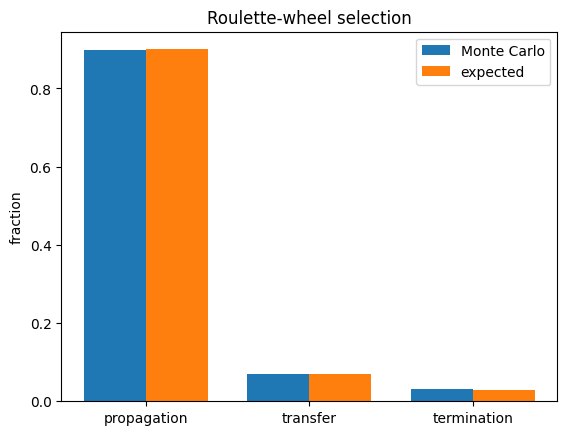

In [15]:
#@title Plot chosen vs. expected fractions
idx = np.arange(3); w = 0.38
plt.bar(idx - w/2, np.array(counts)/sum(counts), w, label="Monte Carlo")
plt.bar(idx + w/2, np.array(rates)/sum(rates), w, label="expected")
plt.xticks(idx, events); plt.ylabel("fraction"); plt.legend(); plt.title("Roulette-wheel selection"); plt.show()

## 5 · Trick #4 — "When does it happen?" (waiting times)
If events happen at a total rate `R` (per second), the time until the next one is

$$\tau = \frac{1}{R}\ln\frac{1}{Rnd}$$

That's the clock of the Gillespie algorithm (Notebooks 6–7).

In [16]:
R = 2.0                                # events per second
waits = []
for i in range(50_000):
    tau = np.log(1 / random.random()) / R
    waits.append(tau)

print(f"average waiting time: {np.mean(waits):.3f} s   (expected 1/R = {1/R} s)")

average waiting time: 0.503 s   (expected 1/R = 0.5 s)


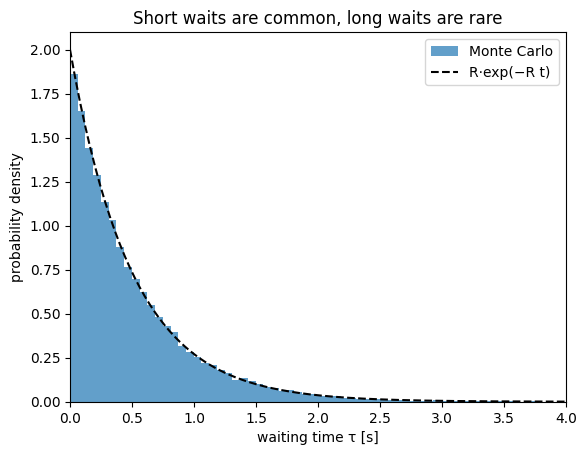

In [17]:
#@title Plot the waiting-time distribution
t = np.linspace(0, 4, 200)
plt.hist(waits, bins=80, density=True, alpha=0.7, label="Monte Carlo")
plt.plot(t, R*np.exp(-R*t), "k--", label="R·exp(−R t)")
plt.xlim(0, 4); plt.xlabel("waiting time τ [s]"); plt.ylabel("probability density"); plt.legend()
plt.title("Short waits are common, long waits are rare"); plt.show()

## 6 · A statistics example: who wins Snakes and Ladders?
Maryam, Tala and Jad play **Snakes and Ladders** on the classic 100-square board, taking turns in that order with one die. A ladder's foot sends you up; a snake's head sends you down. You must land **exactly** on 100; if the roll overshoots, you stay where you are.

Two questions that are hard to answer with pen and paper:
1. How many rounds does a game take?
2. Does going first give Maryam an advantage, and how big is it?

Monte Carlo answers both by playing the game thousands of times.

### 6.1 · The board
Each ladder and snake is a jump from one square to another. A dictionary stores them: `{start: end}`.

In [18]:
LADDERS = {1: 38, 4: 14, 9: 31, 21: 42, 28: 84, 36: 44, 51: 67, 71: 91, 80: 100}
SNAKES = {16: 6, 47: 26, 49: 11, 56: 53, 62: 19, 64: 60, 87: 24, 93: 73, 95: 75, 98: 78}

Put both in one dictionary, `JUMPS`, so one lookup handles ladders and snakes:

In [19]:
JUMPS = {}
JUMPS.update(LADDERS)
JUMPS.update(SNAKES)

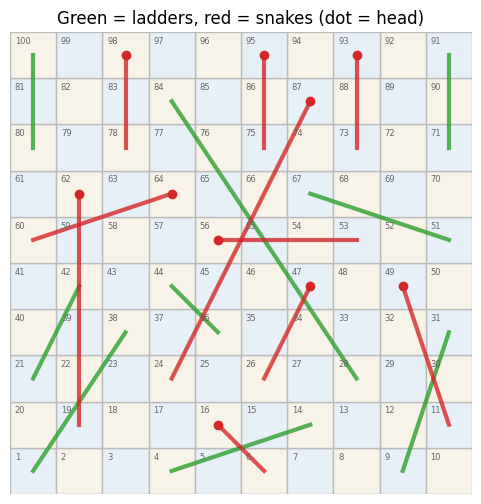

In [20]:
#@title Draw the board
def square_xy(sq):
    row, col = divmod(sq - 1, 10)
    return (col if row % 2 == 0 else 9 - col) + 0.5, row + 0.5
fig, ax = plt.subplots(figsize=(6, 6))
for sq in range(1, 101):
    x, y = square_xy(sq)
    ax.add_patch(plt.Rectangle((x-0.5, y-0.5), 1, 1, fc="#f7f3e8" if (int(x)+int(y)) % 2 else "#e8f0f7", ec="#bbb"))
    ax.text(x-0.4, y+0.25, sq, fontsize=6, color="#666")
for a, b in LADDERS.items():
    (x0, y0), (x1, y1) = square_xy(a), square_xy(b); ax.plot([x0, x1], [y0, y1], c="tab:green", lw=3, alpha=0.8)
for a, b in SNAKES.items():
    (x0, y0), (x1, y1) = square_xy(a), square_xy(b); ax.plot([x0, x1], [y0, y1], c="tab:red", lw=3, alpha=0.8)
    ax.plot(x0, y0, "o", c="tab:red", ms=6)
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Green = ladders, red = snakes (dot = head)"); plt.show()

### 6.2 · One move
A move is a small chain of random events: roll the die → move (unless that overshoots 100) → climb a ladder or slide down a snake.

`random.randint(1, 6)` gives a whole number from 1 to 6, like a die.

In [21]:
def move(position):
    target = position + random.randint(1, 6)   # roll the die
    if target > 100:                           # overshoot: stay
        return position
    if target in JUMPS:                        # ladder or snake
        return JUMPS[target]
    return target

### 6.3 · One game
`positions` holds where each player is (all start at 0). Each round, Maryam (player 0), Tala (1) and Jad (2) move in turn. The first to reach 100 wins.

In [22]:
players = ["Maryam", "Tala", "Jad"]

def play_game():
    positions = [0, 0, 0]
    rounds = 0
    while True:
        rounds += 1
        for i in range(3):
            positions[i] = move(positions[i])
            if positions[i] == 100:
                return i, rounds          # winner, number of rounds

In [23]:
winner, rounds = play_game()
print(f"{players[winner]} wins after {rounds} rounds")

Maryam wins after 19 rounds


### 6.4 · Play 100,000 games
Count the wins of each player and keep the length of every game.

In [24]:
N_games = 100_000
wins = [0, 0, 0]
game_lengths = []

for g in range(N_games):
    winner, rounds = play_game()
    wins[winner] += 1
    game_lengths.append(rounds)

In [25]:
for i in range(3):
    print(f"{players[i]:7s} wins {wins[i] / N_games:.2%} of games")

print(f"average game: {np.mean(game_lengths):.1f} rounds")

Maryam  wins 34.27% of games
Tala    wins 33.39% of games
Jad     wins 32.34% of games
average game: 21.8 rounds


### 6.5 · ✅ Validation: the exact answer
This game has an exact solution: a player's next square depends only on the current square (a **Markov chain**). Following the probability of being on each square, turn by turn, gives the exact chance of finishing on each turn, and from that each player's exact chance of winning.

The maths is in the collapsed cell below; you don't need it to follow the rest.

In [26]:
#@title Exact solution from a Markov chain (optional)
Tm = np.zeros((101, 101))                       # transition matrix, squares 0..100
for s in range(100):
    for d in range(1, 7):
        t = s + d
        Tm[s, s if t > 100 else JUMPS.get(t, t)] += 1/6
Tm[100, 100] = 1
p = np.zeros(101); p[0] = 1; done = [0.0]
for _ in range(400):
    p = p @ Tm; done.append(p[100])             # P(finished by turn t)
done = np.array(done); f_t = np.diff(done); S = 1 - done; t = np.arange(1, len(f_t) + 1)
exact = np.array([np.sum(f_t * S[t]**i * S[t-1]**(2-i)) for i in range(3)])
exact = exact / exact.sum()
rounds_exact = S[t-1]**3 - S[t]**3              # P(game lasts exactly t rounds)
print("exact winning chances computed")

exact winning chances computed


In [27]:
for i in range(3):
    noise = np.sqrt(exact[i] * (1 - exact[i]) / N_games)
    print(f"{players[i]:7s} Monte Carlo = {wins[i]/N_games:.4f} ± {noise:.4f}   exact = {exact[i]:.4f}")

Maryam  Monte Carlo = 0.3427 ± 0.0015   exact = 0.3430
Tala    Monte Carlo = 0.3339 ± 0.0015   exact = 0.3332
Jad     Monte Carlo = 0.3234 ± 0.0015   exact = 0.3238


The Monte Carlo values land within a few times the noise (±) of the exact values; a difference of 2–3 noise units happens now and then. As a check, a run of 4 million games gives 0.3429 / 0.3330 / 0.3241, right on the exact answer.

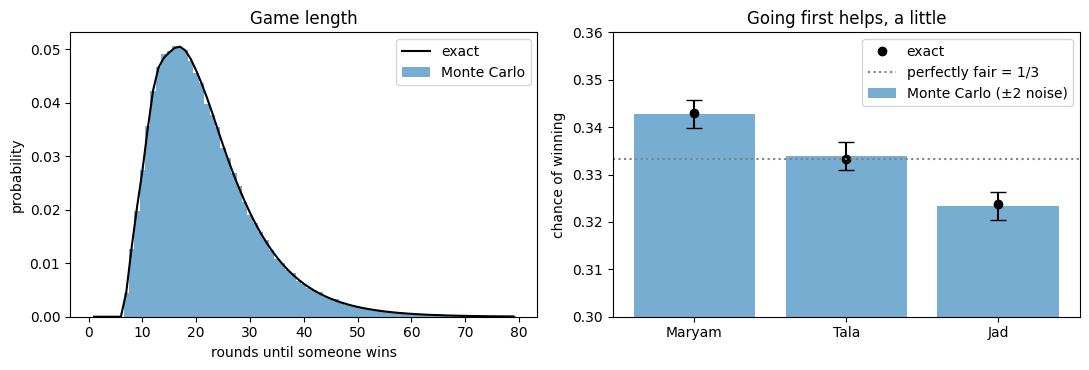

In [28]:
#@title Plot game length and winning chances
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
k = np.arange(1, 80)
ax[0].bar(k, np.bincount(game_lengths, minlength=80)[1:80]/N_games, width=1, alpha=0.6, label="Monte Carlo")
ax[0].plot(k, rounds_exact[:79], "k-", label="exact")
ax[0].set_xlabel("rounds until someone wins"); ax[0].set_ylabel("probability"); ax[0].legend(); ax[0].set_title("Game length")
sigma = np.sqrt(exact*(1 - exact)/N_games)
ax[1].bar(players, np.array(wins)/N_games, yerr=2*sigma, capsize=6, alpha=0.6, label="Monte Carlo (±2 noise)")
ax[1].plot(players, exact, "ko", label="exact")
ax[1].axhline(1/3, ls=":", c="gray", label="perfectly fair = 1/3")
ax[1].set_ylim(0.3, 0.36); ax[1].set_ylabel("chance of winning"); ax[1].legend(); ax[1].set_title("Going first helps, a little")
plt.tight_layout(); plt.show()

### 6.6 · How many games do you need to see the advantage?
Going first is worth only about 2 percentage points. With few games, the noise (Trick #2) is bigger than the effect itself.

In [29]:
def count_wins(N):
    wins = [0, 0, 0]
    for g in range(N):
        winner, rounds = play_game()
        wins[winner] += 1
    return wins

In [30]:
for N in [100, 1_000, 10_000]:
    w = count_wins(N)
    print(f"N = {N:>6,}:  Maryam {w[0]/N:.3f}   Tala {w[1]/N:.3f}   Jad {w[2]/N:.3f}")

N =    100:  Maryam 0.360   Tala 0.330   Jad 0.310
N =  1,000:  Maryam 0.360   Tala 0.328   Jad 0.312


N = 10,000:  Maryam 0.343   Tala 0.332   Jad 0.325


## 7 · Building a Monte Carlo decision tree: a molecule in a reactor with recycle
This last example is the most important one here. It has nothing to do with polymers, yet it has **exactly** the structure of the steady state algorithms in the book: a chain of yes/no decisions, each with its own probability, and a loop that can repeat many times.

**The process.** A molecule of reactant A enters a reactor. On each pass:

| Node | Question | Probability |
|---|---|---|
| ① Reactor | Does A react on this pass? | `P_rxn = 0.30` |
| ② Selectivity | If it reacts, does it form the desired product B (otherwise by-product C)? | `P_sel = 0.85` |
| ③ Product separator | Is B recovered (otherwise lost to waste)? | `P_recB = 0.95` |
| ④ Recycle separator | If A did not react, is it recycled (otherwise purged)? | `P_rec = 0.90` |

A recycled molecule goes **back to node ①**: that's the loop.

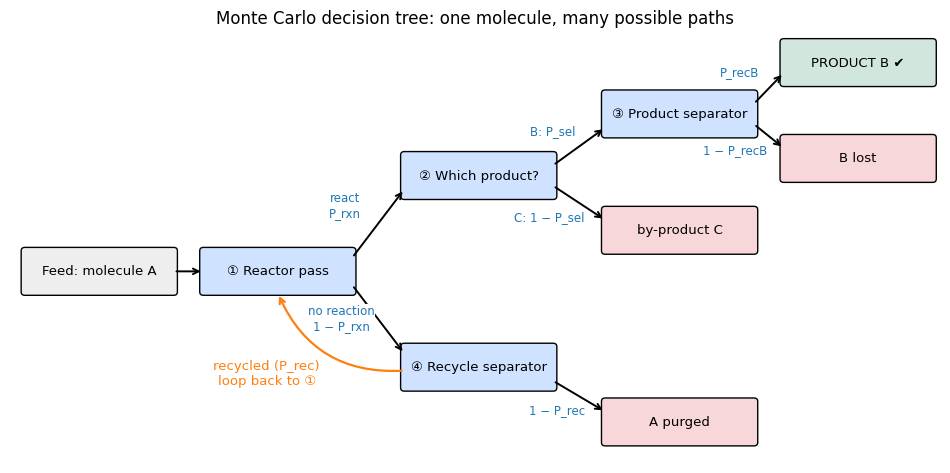

In [31]:
#@title Draw the decision tree
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.axis("off"); ax.set_xlim(-0.3, 12.2); ax.set_ylim(0.4, 6.7)
def box(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x-1.0, y-0.3), 2.0, 0.6, boxstyle="round,pad=0.05", fc=color, ec="k"))
    ax.text(x, y, text, ha="center", va="center", fontsize=9.5)
def arrow(x0, y0, x1, y1, label="", dx=0, dy=0.18):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=1.4))
    if label: ax.text((x0+x1)/2 + dx, (y0+y1)/2 + dy, label, ha="center", fontsize=8.5, color="tab:blue", bbox=dict(fc="white", ec="none", pad=0.5))
box(0.9, 3.2, "Feed: molecule A", "#eeeeee"); box(3.3, 3.2, "① Reactor pass", "#cfe2ff")
box(6.0, 4.6, "② Which product?", "#cfe2ff"); box(6.0, 1.8, "④ Recycle separator", "#cfe2ff")
box(8.7, 5.5, "③ Product separator", "#cfe2ff"); box(8.7, 3.8, "by-product C", "#f8d7da"); box(8.7, 1.0, "A purged", "#f8d7da")
box(11.1, 6.25, "PRODUCT B ✔", "#d1e7dd"); box(11.1, 4.85, "B lost", "#f8d7da")
arrow(1.9, 3.2, 2.3, 3.2)
arrow(4.3, 3.4, 5.0, 4.4, "react\nP_rxn", dx=-0.45, dy=0.1); arrow(4.3, 3.0, 5.0, 2.0, "no reaction\n1 − P_rxn", dx=-0.5, dy=-0.15)
arrow(7.0, 4.75, 7.7, 5.3, "B: P_sel", dx=-0.35); arrow(7.0, 4.45, 7.7, 3.95, "C: 1 − P_sel", dx=-0.4, dy=-0.25)
arrow(9.7, 5.65, 10.1, 6.1, "P_recB", dx=-0.4); arrow(9.7, 5.35, 10.1, 5.0, "1 − P_recB", dx=-0.45, dy=-0.25)
arrow(7.0, 1.6, 7.7, 1.15, "1 − P_rec", dx=-0.3, dy=-0.25)
ax.annotate("", (3.3, 2.88), (5.0, 1.75), arrowprops=dict(arrowstyle="->", lw=1.6, color="tab:orange", connectionstyle="arc3,rad=-0.35"))
ax.text(3.15, 1.55, "recycled (P_rec)\nloop back to ①", color="tab:orange", fontsize=9.5, ha="center")
ax.set_title("Monte Carlo decision tree: one molecule, many possible paths"); plt.show()

### 7.1 · One molecule
The code is a direct translation of the tree: one `if Rnd ≤ P` per node, and a `while` loop for the recycle. It returns where the molecule ended up and how many passes it made.

In [32]:
P_rxn = 0.30      # ① probability of reacting on a pass
P_sel = 0.85      # ② probability that the product is B
P_recB = 0.95     # ③ probability that B is recovered

In [33]:
def one_molecule(P_rec):
    passes = 0
    while True:
        passes += 1
        if random.random() <= P_rxn:              # ① reacts?
            if random.random() <= P_sel:          # ② product B?
                if random.random() <= P_recB:     # ③ recovered?
                    return "product B", passes
                return "B lost", passes
            return "by-product C", passes
        if random.random() > P_rec:               # ④ not recycled
            return "A purged", passes

In [34]:
for k in range(5):
    outcome, passes = one_molecule(0.90)
    print(f"molecule {k + 1}: {outcome} after {passes} pass(es)")

molecule 1: product B after 4 pass(es)
molecule 2: A purged after 3 pass(es)
molecule 3: product B after 1 pass(es)
molecule 4: product B after 9 pass(es)
molecule 5: product B after 5 pass(es)


### 7.2 · Many molecules
Simulate 100,000 molecules. A dictionary counts the outcomes, and a list keeps the number of passes.

In [35]:
N = 100_000
counts = {"product B": 0, "B lost": 0, "by-product C": 0, "A purged": 0}
all_passes = []

for i in range(N):
    outcome, passes = one_molecule(0.90)
    counts[outcome] += 1
    all_passes.append(passes)

This tree is simple enough to solve exactly, which lets us check the code. The chance of going around the loop once is `q = (1 − P_rxn)·P_rec`, and the chance that a molecule eventually reacts is `P_rxn / (1 − q)`:

In [36]:
P_rec = 0.90
q = (1 - P_rxn) * P_rec
p_react = P_rxn / (1 - q)

exact = {"product B": p_react * P_sel * P_recB,
         "B lost": p_react * P_sel * (1 - P_recB),
         "by-product C": p_react * (1 - P_sel),
         "A purged": (1 - P_rxn) * (1 - P_rec) / (1 - q)}

In [37]:
for outcome in counts:
    print(f"{outcome:13s} Monte Carlo = {counts[outcome] / N:.4f}   exact = {exact[outcome]:.4f}")

product B     Monte Carlo = 0.6553   exact = 0.6547
B lost        Monte Carlo = 0.0341   exact = 0.0345
by-product C  Monte Carlo = 0.1212   exact = 0.1216
A purged      Monte Carlo = 0.1895   exact = 0.1892


### 7.3 · How many passes? A chain length distribution in disguise
Each extra pass happens with probability `q`, just like a chain adding one more monomer with probability `P_p`. The number of passes follows a **geometric distribution**, the same shape as the Flory distribution in Notebook 2.

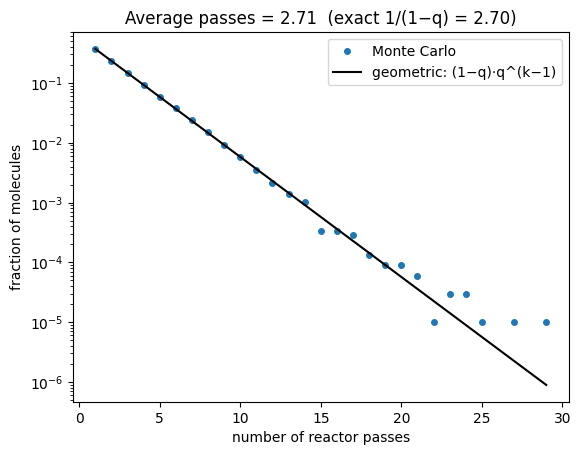

In [38]:
#@title Plot the number of passes
passes_arr = np.array(all_passes); k = np.arange(1, passes_arr.max() + 1)
plt.semilogy(k, np.bincount(passes_arr)[1:] / N, "o", ms=4, label="Monte Carlo")
plt.semilogy(k, (1-q)*q**(k-1), "k-", label="geometric: (1−q)·q^(k−1)")
plt.xlabel("number of reactor passes"); plt.ylabel("fraction of molecules"); plt.legend()
plt.title(f"Average passes = {passes_arr.mean():.2f}  (exact 1/(1−q) = {1/(1-q):.2f})"); plt.show()

### 7.4 · Use the model: how much recycle?
More recycle means fewer molecules purged, but also more chances to form the by-product, and more passes through the reactor. Scan the recycle probability and see where the molecules go.

In [39]:
def outcome_fractions(P_rec, N=20_000):
    counts = {"product B": 0, "B lost": 0, "by-product C": 0, "A purged": 0}
    for i in range(N):
        outcome, passes = one_molecule(P_rec)
        counts[outcome] += 1
    return counts

In [40]:
recycle_values = np.linspace(0, 0.98, 15)
results = []
for P_rec in recycle_values:
    results.append(outcome_fractions(P_rec))

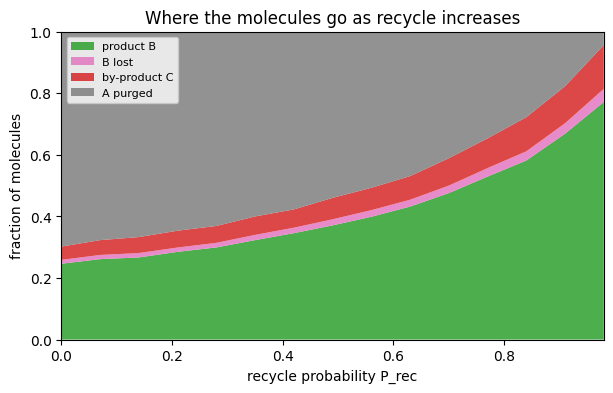

In [41]:
#@title Plot where the molecules go
names = ["product B", "B lost", "by-product C", "A purged"]
fractions = np.array([[r[name]/20_000 for r in results] for name in names])
plt.figure(figsize=(7, 4))
plt.stackplot(recycle_values, fractions, labels=names, colors=["tab:green", "tab:pink", "tab:red", "tab:gray"], alpha=0.85)
plt.xlabel("recycle probability P_rec"); plt.ylabel("fraction of molecules"); plt.xlim(0, 0.98); plt.ylim(0, 1)
plt.legend(loc="upper left", fontsize=8); plt.title("Where the molecules go as recycle increases"); plt.show()

### 7.5 · From this tree to a polymer chain
| Reactor with recycle | Steady state polymerization (book Ch. 3) |
|---|---|
| one molecule of A | one polymer radical (living chain) |
| one more reactor pass (`Rnd ≤ q`) | one more monomer added (`Rnd ≤ P_p`) |
| number of passes | chain length `n` |
| node ②: B or C? | which termination: combination or transfer? |
| node ③: recovered or lost? | which monomer re-initiates after transfer? |
| constant probabilities → molecules one after another | constant probabilities → chains one after another |

The probabilities here never change, which makes this a **steady state** model. If the reactor conditions drifted with time, the probabilities would change too, and we'd need a **dynamic** model: that's Gillespie's method (Notebook 6).

## ✅ Recap: your Monte Carlo toolbox
| Trick | Code | Used for |
|---|---|---|
| 1 · Does it happen? | `if random.random() <= P:` | propagate or stop, which monomer adds, each node of a tree |
| 2 · Count to estimate | repeat N times, then average | averages, distributions (noise ~ 1/√N) |
| 3 · Which one happens? | `pick_event(rates)` | choosing the next reaction |
| 4 · When? | `np.log(1/random.random()) / R` | the clock in dynamic Monte Carlo |

### 🧪 Try it yourself
1. Make the coin unfair (`P = 0.3`). How many flips until the fraction stays within 0.01 of 0.3?
2. In Snakes and Ladders, change the rule so an overshoot bounces back (at 97, a 5 takes you to 98). Does the game get longer?
3. In the reactor, add a fifth node: product B decomposes in the separator with probability 0.02. Where does it go in the tree?
4. Simulate only 500 molecules several times. How much do the outcome fractions jump around?

➡️ **Next: Notebook 2 — Chain growth & molecular weight distributions**